# Days of coverage: freight routes and supplier urgency

Coverage is the number of business days from today until projected stock first goes negative, the next back-order date. Two decisions read it:

- **Freight routing**: plenty of time takes the cheapest, slowest lane; tight takes a faster lane; imminent takes air.
- **Supplier urgency**: suppliers who cannot see our data get one of five actions per item: critical, rush, urgent, OK, or slow down.

Both decisions read the same number, so they share one function. This is the logic behind the write-ups *Freight routing from days of coverage* and the supplier coverage report in *Dashboards for vendors, retailers and the warehouse*.

> Clean-room version. Items, quantities and thresholds are generated or illustrative.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd

from supply_ops import coverage, synthetic
from supply_ops.config import ROUTES, TIERS
from supply_ops.plots import coverage_routes
from supply_ops.synthetic import AS_OF

items, events = synthetic.supply_events()
domestic = int((items["family"] == "domestic").sum())
print(f"{len(items)} items ({domestic} domestic, {len(items) - domestic} international), "
      f"{len(events):,} dated supply and demand events, today {AS_OF:%Y-%m-%d}")

60 items (40 domestic, 20 international), 1,612 dated supply and demand events, today 2026-07-01


## 1. Coverage, roll-forward style

Start from on-hand stock, add every receipt and subtract every demand in date order, and find the first day the running total goes negative. No shortfall inside the horizon is its own answer: *none ahead*.

In [2]:
live = coverage.plan(items, events, AS_OF)
live.head(10)

,item,family,on_hand,coverage_days,route,supplier_tier
0,S-001,domestic,10208,10.0,air,rush
1,S-002,domestic,3525,20.0,fast lane,urgent
2,S-003,domestic,11776,125.0,slow lane,excess
3,S-004,domestic,531,0.0,air,rush
4,S-005,domestic,4755,5.0,air,rush
5,S-006,domestic,1127,0.0,air,rush
6,S-007,domestic,15818,20.0,fast lane,urgent
7,S-008,domestic,166,0.0,air,rush
8,S-009,domestic,7564,15.0,fast lane,urgent
9,S-010,domestic,498,5.0,air,rush


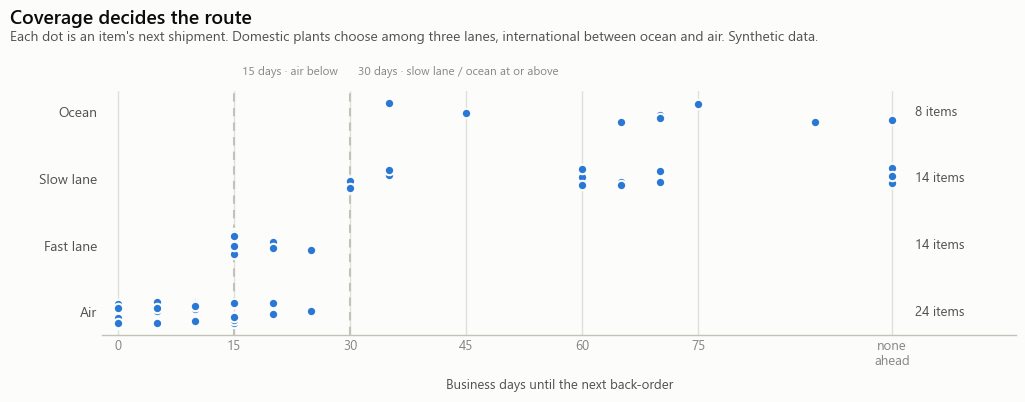

In [3]:
coverage_routes(live, path=ROOT / "images" / "coverage_routes.png");

In [4]:
pd.crosstab(live["family"], live["route"], margins=True)

route,air,fast lane,ocean,slow lane,All
family,,,,,
domestic,12,14,0,14,40
international,12,0,8,0,20
All,24,14,8,14,60


## 2. The same number tells a supplier what to do

Thresholds in business days: rush under 15, urgent under 30, OK under 60, slow down at or above it. No stock at all is critical whatever is on its way.

In [5]:
order = ["critical", "rush", "urgent", "ok", "excess"]
live["supplier_tier"].value_counts().reindex(order, fill_value=0).rename("items").to_frame()

,items
supplier_tier,
critical,0
rush,17
urgent,21
ok,6
excess,16


## 3. A stale stock figure changes the call

The supply-and-demand schedule is refreshed overnight; stock is refreshed through the day. Reading stock from the overnight snapshot misses this morning's receipts, and for some items that is the difference between air and a slower lane.

In [6]:
stale = coverage.plan(items, events, AS_OF, stock_column="snapshot_on_hand")
both = live.merge(stale, on=["item", "family"], suffixes=("_live", "_snapshot"))
changed = both[(both["route_live"] != both["route_snapshot"]) |
               (both["supplier_tier_live"] != both["supplier_tier_snapshot"])]
print(f"{len(changed)} of {len(live)} items get a different route or tier from the stale figure")
changed[["item", "on_hand_snapshot", "on_hand_live", "coverage_days_snapshot", "coverage_days_live",
         "route_snapshot", "route_live", "supplier_tier_snapshot", "supplier_tier_live"]]

4 of 60 items get a different route or tier from the stale figure


,item,on_hand_snapshot,on_hand_live,coverage_days_snapshot,coverage_days_live,route_snapshot,route_live,supplier_tier_snapshot,supplier_tier_live
8,S-009,2042,7564,5.0,15.0,air,fast lane,rush,urgent
13,S-014,2736,5451,5.0,15.0,air,fast lane,rush,urgent
22,S-023,7668,10722,10.0,15.0,air,fast lane,rush,urgent
39,S-040,3772,5664,10.0,15.0,air,fast lane,rush,urgent


## Key findings

- One coverage number drives both the freight route and the supplier's urgency, so the two cannot disagree with each other.
- "No back-order ahead" is its own answer, not a large number: it routes to the cheapest lane and tells a supplier to slow down.
- Read stock from the freshest source. A snapshot a few hours old flips the call on a handful of items, and always toward the more expensive or more urgent answer.